Sample 4
Parameters: [3.796191 0.159326 0.988477 0.442627]
Hellinger distance = 0.016575
PDF已保存：landscape_test_4_threshold_0.01.pdf


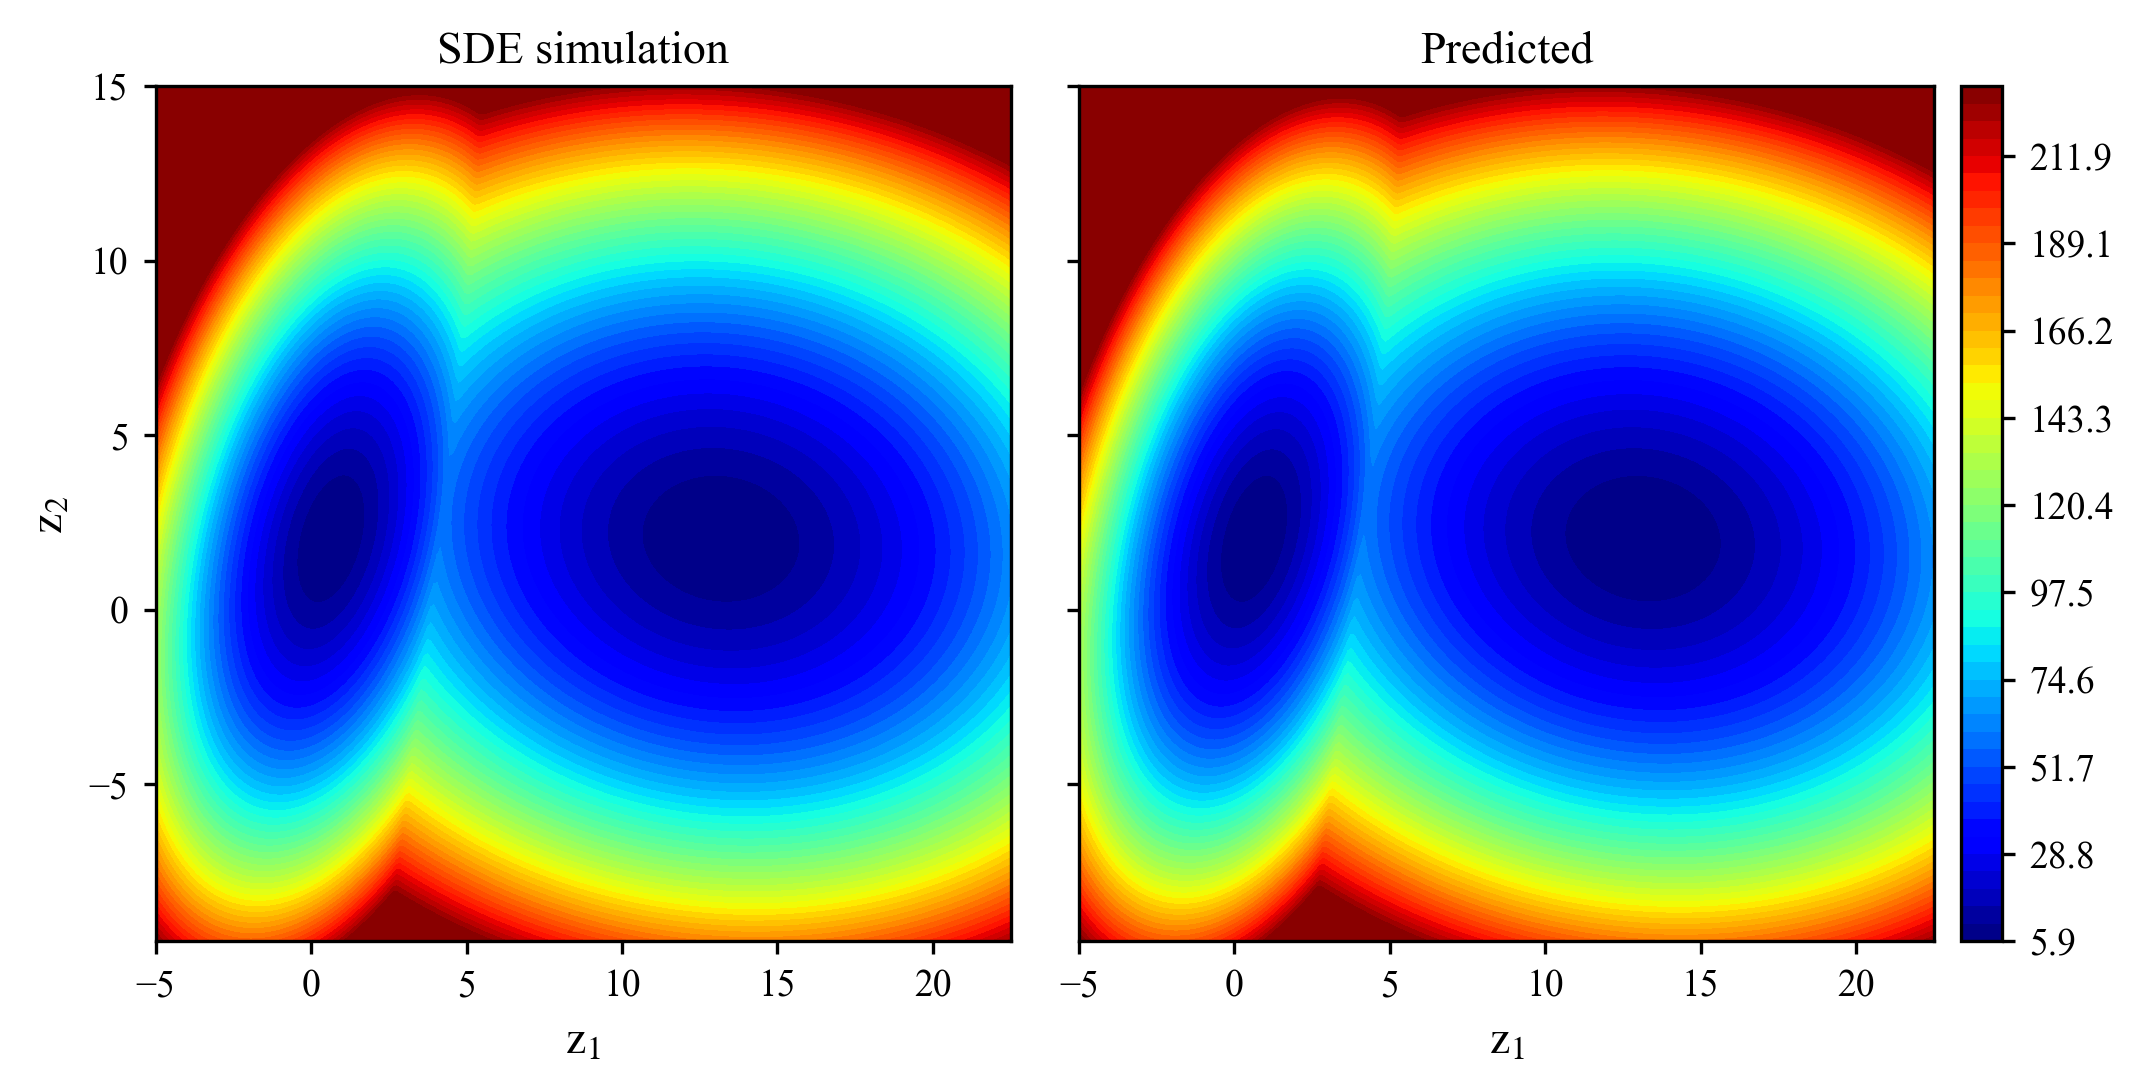

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from scipy.io import loadmat
from scipy.stats import multivariate_normal


# ======================== 绘图风格 ========================
plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "stix",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# ======================== 模型定义 ========================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=3,
                 hidden_dims=(512, 1024, 512)):
        super().__init__()
        self.num_components = num_components
        dims = [input_dim, *hidden_dims]
        self.hidden_layers = nn.ModuleList(
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(dims) - 1)
        )
        self.output_layer = nn.Linear(
            hidden_dims[-1], num_components * 6
        )

    def forward(self, x):
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        out = self.output_layer(x).view(
            -1, self.num_components, 6
        )

        weights = F.softmax(out[:, :, 0], dim=1)
        means = out[:, :, 1:3]

        s_xx = F.softplus(out[:, :, 3]) + 1e-6
        rho = torch.clamp(
            2 * torch.sigmoid(out[:, :, 4]) - 1,
            -1 + 1e-4,
            1 - 1e-4
        )
        s_yy = F.softplus(out[:, :, 5]) + 1e-6
        s_xy = rho * torch.sqrt(s_xx * s_yy)

        cov = torch.zeros(
            x.size(0), self.num_components, 2, 2,
            dtype=x.dtype, device=x.device
        )
        cov[:, :, 0, 0] = s_xx
        cov[:, :, 0, 1] = s_xy
        cov[:, :, 1, 0] = s_xy
        cov[:, :, 1, 1] = s_yy

        return weights, means, cov


# ======================== 可修改参数 ========================
MODEL_PATH = (
    "best_model_in4_K3_512-1024-512_"
    "testloss0.097046.pth"
)
CSV_PATH = "ps_test.csv"
MAT_DIR = "density_results_ps_test_edges=0.1（未转置）"
MAT_KEY = "density"

SAMPLE_ID = 4
WEIGHT_THRESHOLD = 0.01
GRID_STEP = 0.1
X_MIN = -9.6
Y_MIN = -9.6

SWAP_XY = True
SAVE_FIG = True

# 设置为None时自动使用完整范围
X_LIM = (-5, 22.5)
Y_LIM = (-9.5, 15)

# 图间距及颜色条设置
WSPACE = 0.08
COLORBAR_PAD = 0.012
COLORBAR_WIDTH = 0.018


# ======================== 读取模型与数据 ========================
model = MixtureOfGaussiansModel()
model.load_state_dict(torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
))
model.eval()

test_data = pd.read_csv(CSV_PATH)

if not 1 <= SAMPLE_ID <= len(test_data):
    raise IndexError(
        f"SAMPLE_ID应在1到{len(test_data)}之间。"
    )

params = test_data.iloc[
    SAMPLE_ID - 1, :4
].to_numpy(dtype=np.float32)

x_input = torch.tensor(
    params[None, :],
    dtype=torch.float32
)

mat_path = os.path.join(
    MAT_DIR,
    f"ps_test{{{SAMPLE_ID}}}.mat"
)

mat_data = loadmat(mat_path)

if MAT_KEY not in mat_data:
    raise KeyError(
        f"{mat_path}中不存在变量'{MAT_KEY}'。"
    )

ref_density = mat_data[MAT_KEY].astype(np.float64)
n_x1, n_x2 = ref_density.shape


# ======================== 坐标网格 ========================
x1 = np.arange(n_x1) * GRID_STEP + GRID_STEP / 2
x2 = np.arange(n_x2) * GRID_STEP + GRID_STEP / 2

X_model, Y_model = np.meshgrid(
    x1, x2, indexing="ij"
)

positions = np.dstack((X_model, Y_model))


# ======================== 模型预测密度 ========================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights = weights[0].numpy()
means = means[0].numpy()
covariances = covariances[0].numpy()

keep = weights >= WEIGHT_THRESHOLD

if not np.any(keep):
    keep[np.argmax(weights)] = True

weights = weights[keep]
weights /= weights.sum()
means = means[keep]
covariances = covariances[keep]

pred_density = np.zeros_like(X_model, dtype=np.float64)

for weight, mean, covariance in zip(
    weights, means, covariances
):
    rv = multivariate_normal(
        mean=mean,
        cov=covariance + np.eye(2) * 1e-8,
        allow_singular=True
    )
    pred_density += weight * rv.pdf(positions)


# ======================== 归一化与Hellinger距离 ========================
ref_density /= ref_density.sum() + 1e-12
pred_density /= pred_density.sum() + 1e-12

hellinger = np.sqrt(
    0.5 * np.sum(
        (
            np.sqrt(ref_density)
            - np.sqrt(pred_density)
        ) ** 2
    )
)

print(f"Sample {SAMPLE_ID}")
print("Parameters:", params)
print(f"Hellinger distance = {hellinger:.6f}")


# ======================== Landscape及绘图坐标 ========================
eps = 1e-100
ref_landscape = -np.log(np.maximum(ref_density, eps))
pred_landscape = -np.log(np.maximum(pred_density, eps))

vmin = min(ref_landscape.min(), pred_landscape.min())
vmax = max(ref_landscape.max(), pred_landscape.max())
levels = np.linspace(vmin, vmax, 50)

X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

if SWAP_XY:
    X_plot, Y_plot = Y_true, X_true
else:
    X_plot, Y_plot = X_true, Y_true

xlim = X_LIM or (
    float(X_plot.min()),
    float(X_plot.max())
)
ylim = Y_LIM or (
    float(Y_plot.min()),
    float(Y_plot.max())
)


# ======================== 绘图 ========================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(7.6, 4.2)
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.13,
    top=0.90,
    wspace=WSPACE
)

cf1 = ax1.contourf(
    X_plot, Y_plot, ref_landscape,
    levels=levels, cmap="jet",
    vmin=vmin, vmax=vmax
)

cf2 = ax2.contourf(
    X_plot, Y_plot, pred_landscape,
    levels=levels, cmap="jet",
    vmin=vmin, vmax=vmax
)

for ax, title in zip(
    (ax1, ax2),
    ("SDE simulation", "Predicted")
):
    ax.set_title(title, pad=6)
    ax.set_xlabel(r"$\mathrm{z}_1$")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        top=False,
        right=False
    )

    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)
    else:
        x_span = xlim[1] - xlim[0]
        y_span = ylim[1] - ylim[0]
        ax.set_aspect(
            x_span / y_span,
            adjustable="box"
        )

ax1.set_ylabel(r"$\mathrm{z}_2$")
ax2.tick_params(axis="y", labelleft=False)

# 颜色条上下边界与右图完全一致
fig.canvas.draw()
pos = ax2.get_position()

cax = fig.add_axes([
    pos.x1 + COLORBAR_PAD,
    pos.y0,
    COLORBAR_WIDTH,
    pos.height
])

cbar = fig.colorbar(cf2, cax=cax)
cbar.ax.tick_params(
    direction="out",
    length=3,
    width=0.8,
    labelsize=9
)


# ======================== 保存 ========================
if SAVE_FIG:
    output_name = (
        f"landscape_test_{SAMPLE_ID}_"
        f"threshold_{WEIGHT_THRESHOLD}.pdf"
    )
    fig.savefig(
        output_name,
        format="pdf",
        dpi=800,
        bbox_inches="tight",
        pad_inches=0.02,
        facecolor="white"
    )
    print(f"PDF已保存：{output_name}")

plt.show()

Sample 330
Parameters: [3.576465 0.350244 1.160742 0.315186]
Hellinger distance = 0.004476
PDF已保存：landscape_test_330_threshold_0.01.pdf


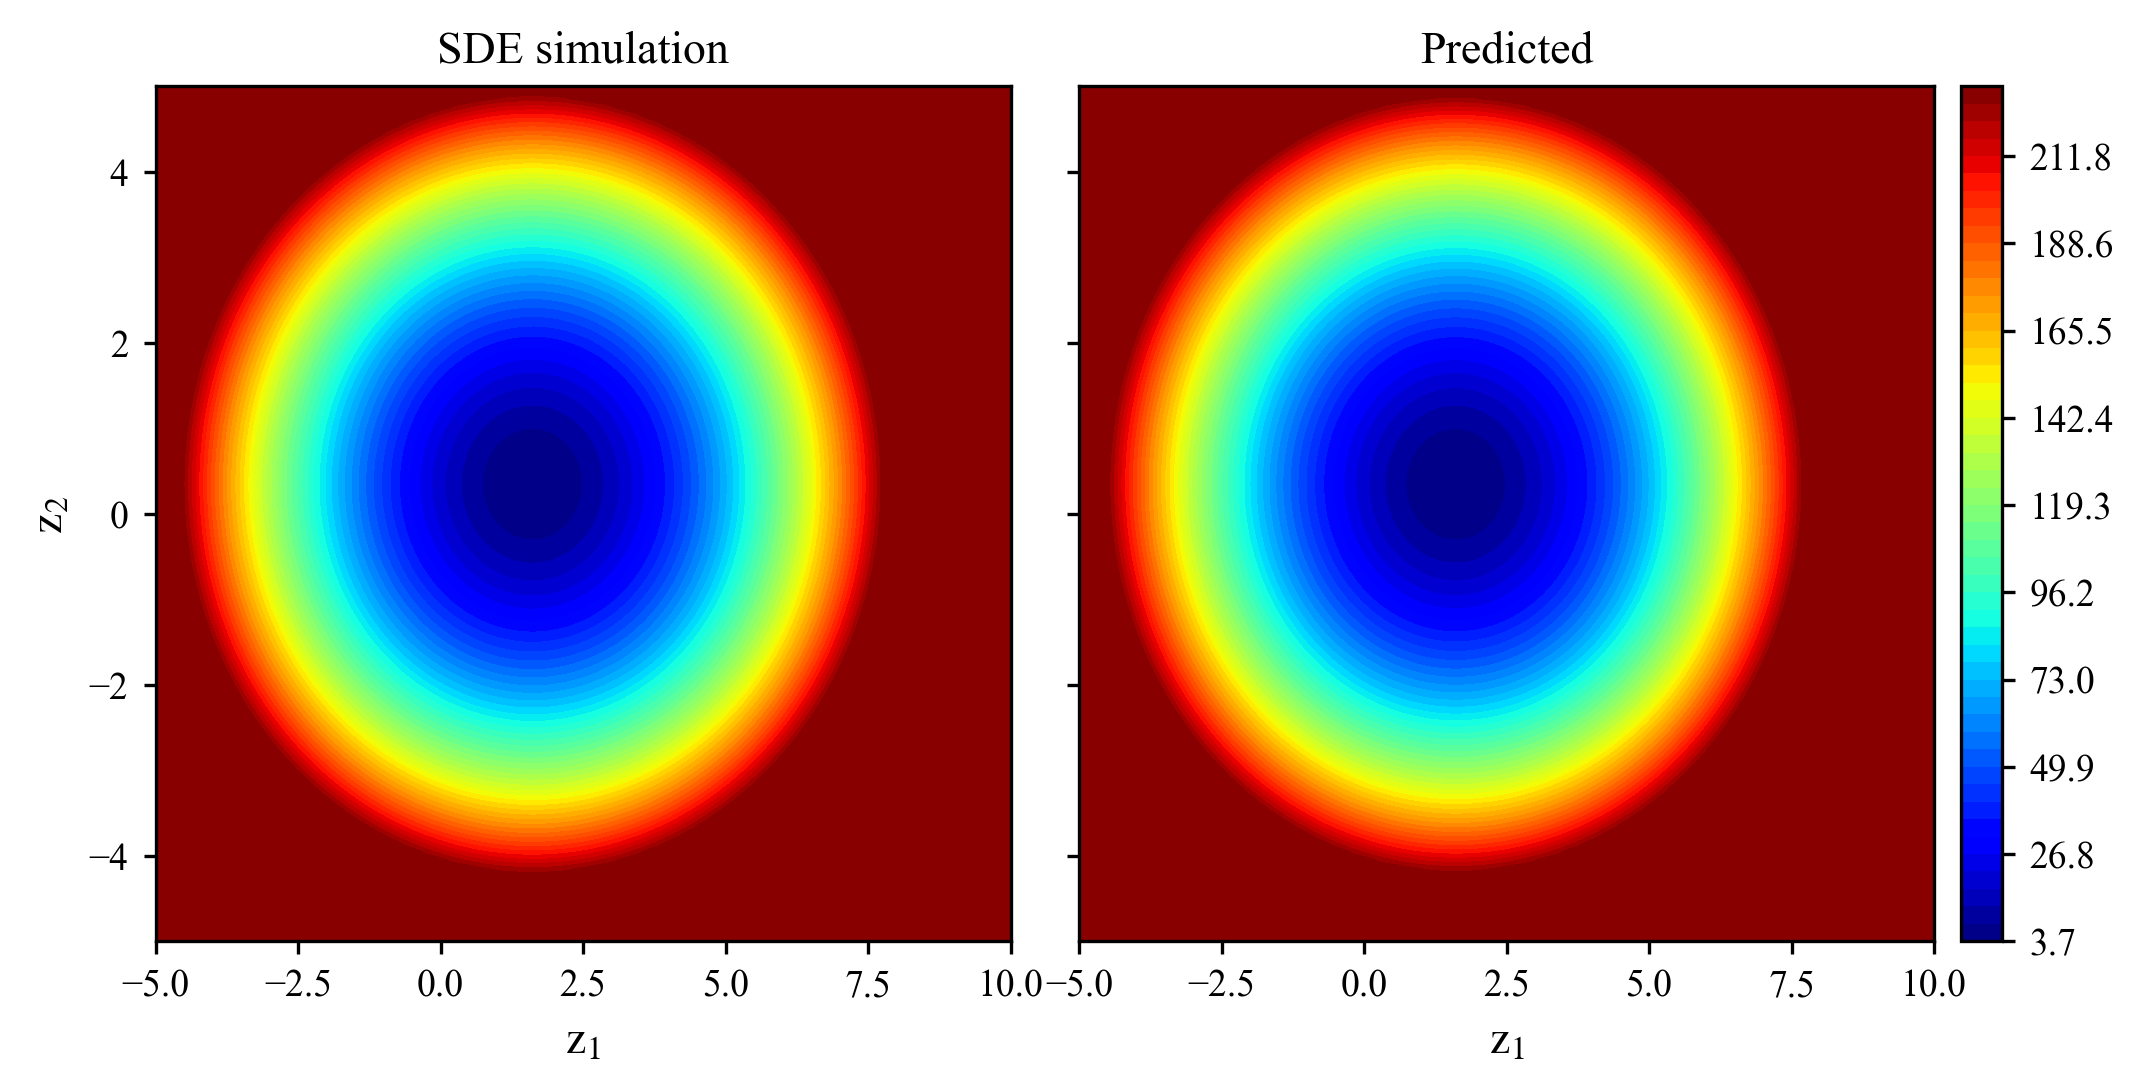

In [3]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from scipy.io import loadmat
from scipy.stats import multivariate_normal


# ======================== 绘图风格 ========================
plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "stix",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# ======================== 模型定义 ========================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=3,
                 hidden_dims=(512, 1024, 512)):
        super().__init__()
        self.num_components = num_components
        dims = [input_dim, *hidden_dims]
        self.hidden_layers = nn.ModuleList(
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(dims) - 1)
        )
        self.output_layer = nn.Linear(
            hidden_dims[-1], num_components * 6
        )

    def forward(self, x):
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        out = self.output_layer(x).view(
            -1, self.num_components, 6
        )

        weights = F.softmax(out[:, :, 0], dim=1)
        means = out[:, :, 1:3]

        s_xx = F.softplus(out[:, :, 3]) + 1e-6
        rho = torch.clamp(
            2 * torch.sigmoid(out[:, :, 4]) - 1,
            -1 + 1e-4,
            1 - 1e-4
        )
        s_yy = F.softplus(out[:, :, 5]) + 1e-6
        s_xy = rho * torch.sqrt(s_xx * s_yy)

        cov = torch.zeros(
            x.size(0), self.num_components, 2, 2,
            dtype=x.dtype, device=x.device
        )
        cov[:, :, 0, 0] = s_xx
        cov[:, :, 0, 1] = s_xy
        cov[:, :, 1, 0] = s_xy
        cov[:, :, 1, 1] = s_yy

        return weights, means, cov


# ======================== 可修改参数 ========================
MODEL_PATH = (
    "best_model_in4_K3_512-1024-512_"
    "testloss0.097046.pth"
)
CSV_PATH = "ps_test.csv"
MAT_DIR = "density_results_ps_test_edges=0.1（未转置）"
MAT_KEY = "density"

SAMPLE_ID = 330
WEIGHT_THRESHOLD = 0.01
GRID_STEP = 0.1
X_MIN = -9.6
Y_MIN = -9.6

SWAP_XY = True
SAVE_FIG = True

# 设置为None时自动使用完整范围
X_LIM = (-5, 10)
Y_LIM = (-5, 5)

# 图间距及颜色条设置
WSPACE = 0.08
COLORBAR_PAD = 0.012
COLORBAR_WIDTH = 0.018


# ======================== 读取模型与数据 ========================
model = MixtureOfGaussiansModel()
model.load_state_dict(torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
))
model.eval()

test_data = pd.read_csv(CSV_PATH)

if not 1 <= SAMPLE_ID <= len(test_data):
    raise IndexError(
        f"SAMPLE_ID应在1到{len(test_data)}之间。"
    )

params = test_data.iloc[
    SAMPLE_ID - 1, :4
].to_numpy(dtype=np.float32)

x_input = torch.tensor(
    params[None, :],
    dtype=torch.float32
)

mat_path = os.path.join(
    MAT_DIR,
    f"ps_test{{{SAMPLE_ID}}}.mat"
)

mat_data = loadmat(mat_path)

if MAT_KEY not in mat_data:
    raise KeyError(
        f"{mat_path}中不存在变量'{MAT_KEY}'。"
    )

ref_density = mat_data[MAT_KEY].astype(np.float64)
n_x1, n_x2 = ref_density.shape


# ======================== 坐标网格 ========================
x1 = np.arange(n_x1) * GRID_STEP + GRID_STEP / 2
x2 = np.arange(n_x2) * GRID_STEP + GRID_STEP / 2

X_model, Y_model = np.meshgrid(
    x1, x2, indexing="ij"
)

positions = np.dstack((X_model, Y_model))


# ======================== 模型预测密度 ========================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights = weights[0].numpy()
means = means[0].numpy()
covariances = covariances[0].numpy()

keep = weights >= WEIGHT_THRESHOLD

if not np.any(keep):
    keep[np.argmax(weights)] = True

weights = weights[keep]
weights /= weights.sum()
means = means[keep]
covariances = covariances[keep]

pred_density = np.zeros_like(X_model, dtype=np.float64)

for weight, mean, covariance in zip(
    weights, means, covariances
):
    rv = multivariate_normal(
        mean=mean,
        cov=covariance + np.eye(2) * 1e-8,
        allow_singular=True
    )
    pred_density += weight * rv.pdf(positions)


# ======================== 归一化与Hellinger距离 ========================
ref_density /= ref_density.sum() + 1e-12
pred_density /= pred_density.sum() + 1e-12

hellinger = np.sqrt(
    0.5 * np.sum(
        (
            np.sqrt(ref_density)
            - np.sqrt(pred_density)
        ) ** 2
    )
)

print(f"Sample {SAMPLE_ID}")
print("Parameters:", params)
print(f"Hellinger distance = {hellinger:.6f}")


# ======================== Landscape及绘图坐标 ========================
eps = 1e-100
ref_landscape = -np.log(np.maximum(ref_density, eps))
pred_landscape = -np.log(np.maximum(pred_density, eps))

vmin = min(ref_landscape.min(), pred_landscape.min())
vmax = max(ref_landscape.max(), pred_landscape.max())
levels = np.linspace(vmin, vmax, 50)

X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

if SWAP_XY:
    X_plot, Y_plot = Y_true, X_true
else:
    X_plot, Y_plot = X_true, Y_true

xlim = X_LIM or (
    float(X_plot.min()),
    float(X_plot.max())
)
ylim = Y_LIM or (
    float(Y_plot.min()),
    float(Y_plot.max())
)


# ======================== 绘图 ========================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(7.6, 4.2)
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.13,
    top=0.90,
    wspace=WSPACE
)

cf1 = ax1.contourf(
    X_plot, Y_plot, ref_landscape,
    levels=levels, cmap="jet",
    vmin=vmin, vmax=vmax
)

cf2 = ax2.contourf(
    X_plot, Y_plot, pred_landscape,
    levels=levels, cmap="jet",
    vmin=vmin, vmax=vmax
)

for ax, title in zip(
    (ax1, ax2),
    ("SDE simulation", "Predicted")
):
    ax.set_title(title, pad=6)
    ax.set_xlabel(r"$\mathrm{z}_1$")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        top=False,
        right=False
    )

    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)
    else:
        x_span = xlim[1] - xlim[0]
        y_span = ylim[1] - ylim[0]
        ax.set_aspect(
            x_span / y_span,
            adjustable="box"
        )

ax1.set_ylabel(r"$\mathrm{z}_2$")
ax2.tick_params(axis="y", labelleft=False)

# 颜色条上下边界与右图完全一致
fig.canvas.draw()
pos = ax2.get_position()

cax = fig.add_axes([
    pos.x1 + COLORBAR_PAD,
    pos.y0,
    COLORBAR_WIDTH,
    pos.height
])

cbar = fig.colorbar(cf2, cax=cax)
cbar.ax.tick_params(
    direction="out",
    length=3,
    width=0.8,
    labelsize=9
)


# ======================== 保存 ========================
if SAVE_FIG:
    output_name = (
        f"landscape_test_{SAMPLE_ID}_"
        f"threshold_{WEIGHT_THRESHOLD}.pdf"
    )
    fig.savefig(
        output_name,
        format="pdf",
        dpi=800,
        bbox_inches="tight",
        pad_inches=0.02,
        facecolor="white"
    )
    print(f"PDF已保存：{output_name}")

plt.show()